# Native GF2 multispectral pansharpening

## Problem, observations and physics

The unknown high-resolution band image $X_b$ is constrained by a lower-resolution multispectral observation $M_b=D(H_b*X_b)+\epsilon_b$ and a broad-band panchromatic image $P=\sum_b a_bX_b+\eta$. Here $D$ is spatial decimation, $H_b$ the unknown sensor blur and $a_b$ its spectral weights. The native author arrays already supply registered observations at a 4:1 pixel ratio. Adaptive Gram-Schmidt fusion regresses the observed low-resolution PAN on centered native spectral bands and transfers intensity residuals through covariance gains. The effective source downsampling is linear; this actual-code convention is preserved explicitly. The local code preserves the original 23-tap interpolation phase, periodic boundaries, centered regression, covariance gains and uint8 quantization.

No high-resolution spectral truth, native PSF or spectral-response vector is supplied. The boxed low-resolution residual and PAN gradient correlation are disclosed diagnostics under a surrogate model; they are not claims of actual sensor likelihood or spectral truth. The supplied scene filename indicates GF2 Beijing; acquisition date, geolocation and physical pixel size are undocumented. This review compares freshly computed interpolation, GSA, equal-band-intensity omission and detail gains, with a fixed display transform throughout.

The active SFIM comparison exposes near-zero/negative matched low-pass radiometry and chromatic speckles in that screened method. GSA was selected after independent original-code quality comparison; SFIM is retained as a real failure comparison, not substituted as fresh GSA.

## Visual contract and evidence roles

The main plate shows native observations and fresh physical reconstruction with honest common scales. Mechanism panels compare actual algorithm components and ablations; sensitivity panels quantify regularization/detail tradeoffs. References are independently captured original-code measurements on exactly these observations, never relabeled as fresh computation. Every displayed fresh variant is calculated in this execution. The private gallery exports vector PDF/SVG and high-resolution PNG from these exact arrays.

In [1]:
from pathlib import Path
import os,sys,time,json
for variable in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS','NUMEXPR_NUM_THREADS']: os.environ[variable]='1'
ROOT=Path.cwd()
if not (ROOT/'src').is_dir(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
from src.preprocessing import load_data
from src.main import run
from src.visualization import review,metrics
print('Kernel executable:',sys.executable)
print('NumPy version:',np.__version__)
started=time.perf_counter()
data=load_data(ROOT/'data/raw_data.npz')
fresh=run(ROOT/'data/raw_data.npz',ROOT/'output/reconstruction.npz')
with np.load(ROOT/'evaluation/baseline_reference.npz',allow_pickle=False) as f: upstream={k:f[k].copy() for k in f.files}
for key in fresh:
    ncc,nrmse=metrics(fresh[key],upstream[key])
    print(f'{key}: NCC={ncc:.16g}, dynamic-range NRMSE={nrmse:.16g}')
print(f'Fresh standard reconstruction: {time.perf_counter()-started:.3f} s')
# Distinct source-run scalar measurements are retained without redundant large arrays.
with np.load(ROOT/'notebooks/reference_outputs/upstream_summary.npz',allow_pickle=False) as f:
    original_summary={k:float(f[k][0]) for k in f.files}
fresh_summary={}
for key,array in fresh.items():
    value=array.astype(float)
    for statistic,number in [('mean',value.mean()),('rms',np.sqrt(np.mean(value**2))),('minimum',value.min()),('maximum',value.max())]:
        fresh_summary[key+'_'+statistic]=np.array([number])
np.savez_compressed(ROOT/'notebooks/reference_outputs/fresh_summary.npz',**fresh_summary)
display(Markdown('| Measurement | Original code run | Fresh local run |\n| --- | ---: | ---: |\n'+'\n'.join(f'| {key} | {number:.10g} | {float(fresh_summary[key][0]):.10g} |' for key,number in original_summary.items())))


Kernel executable: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe
NumPy version: 2.4.6
reconstruction: NCC=1, dynamic-range NRMSE=0
Fresh standard reconstruction: 0.026 s


| Measurement | Original code run | Fresh local run |
| --- | ---: | ---: |
| reconstruction_mean | 60.3602066 | 60.3602066 |
| reconstruction_rms | 74.9473478 | 74.9473478 |
| reconstruction_minimum | 0 | 0 |
| reconstruction_maximum | 255 | 255 |

## Fresh reconstruction, comparisons and sensitivity

The following four figures are produced from local modules. The metric table distinguishes algorithm agreement from observational-consistency diagnostics. A low discrepancy or agreement with a standard method does not establish physical accuracy when independent truth is unavailable.

### 01 native fusion

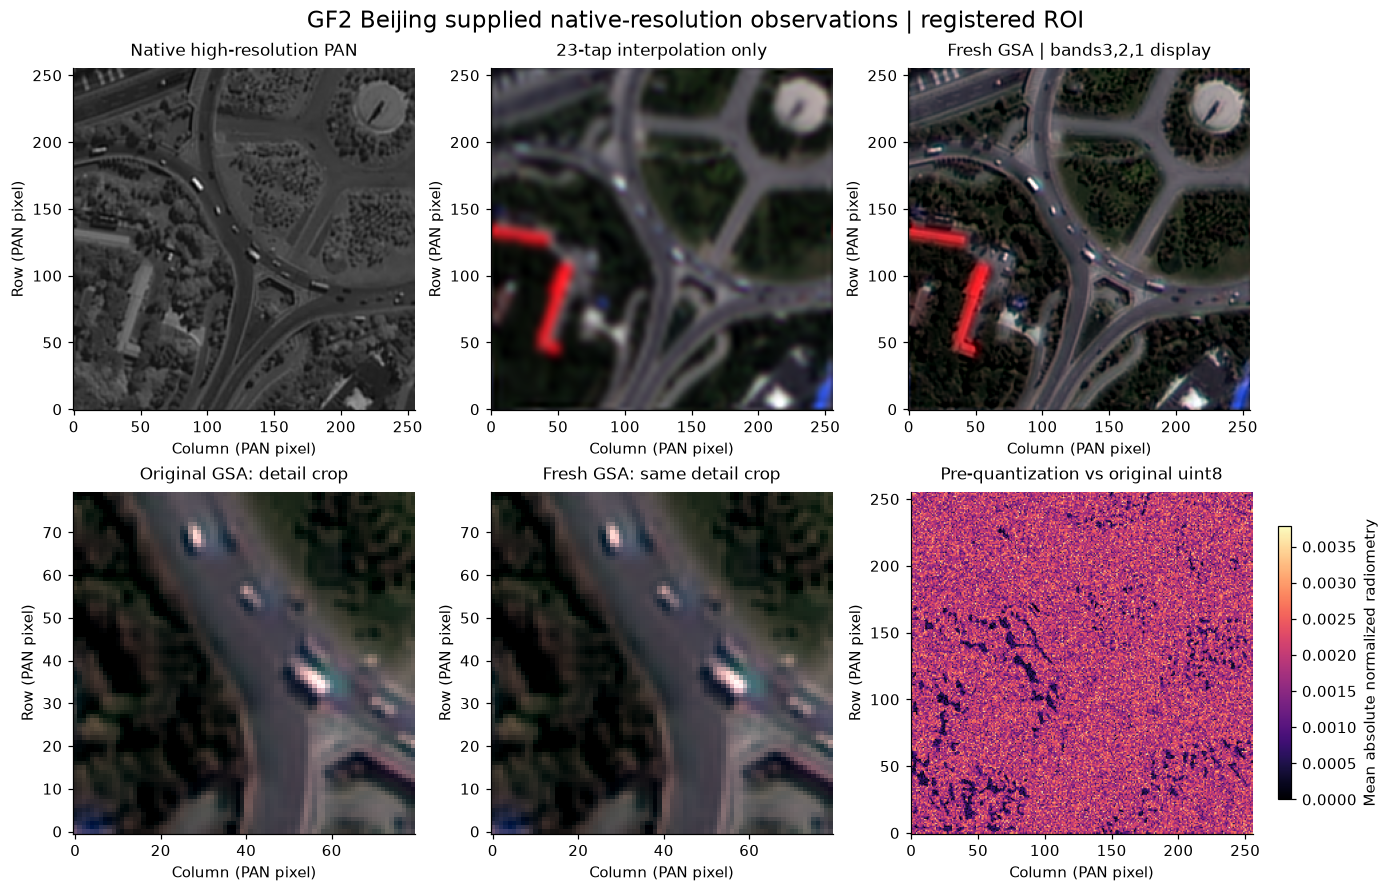

### 02 detail gain

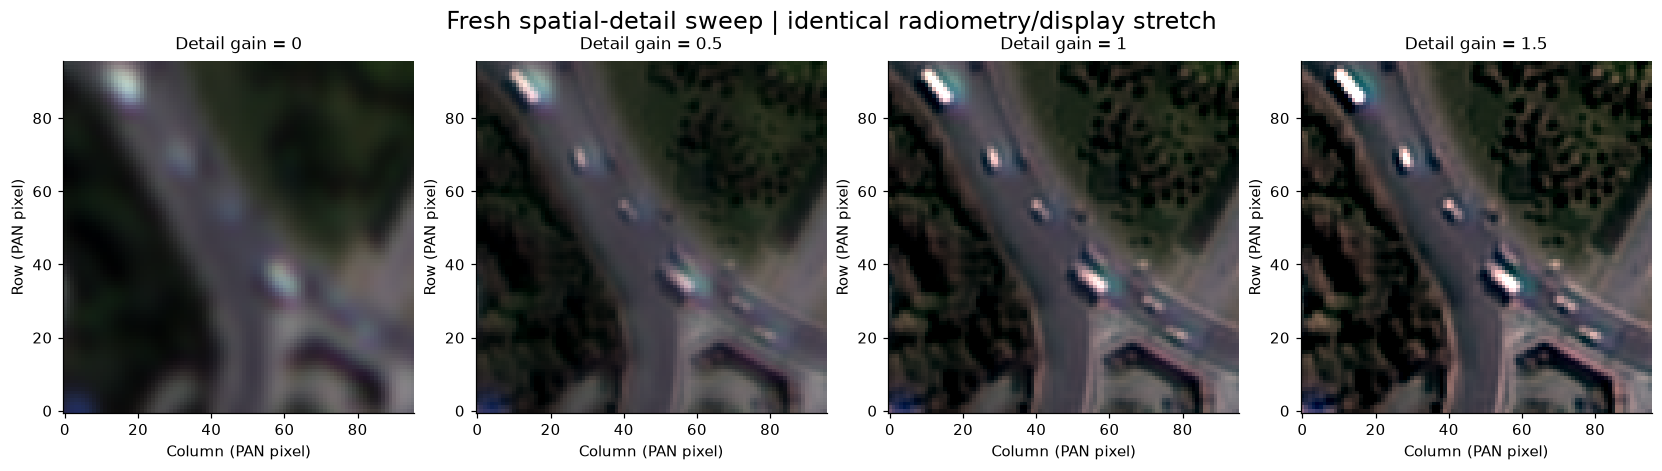

### 03 mechanism

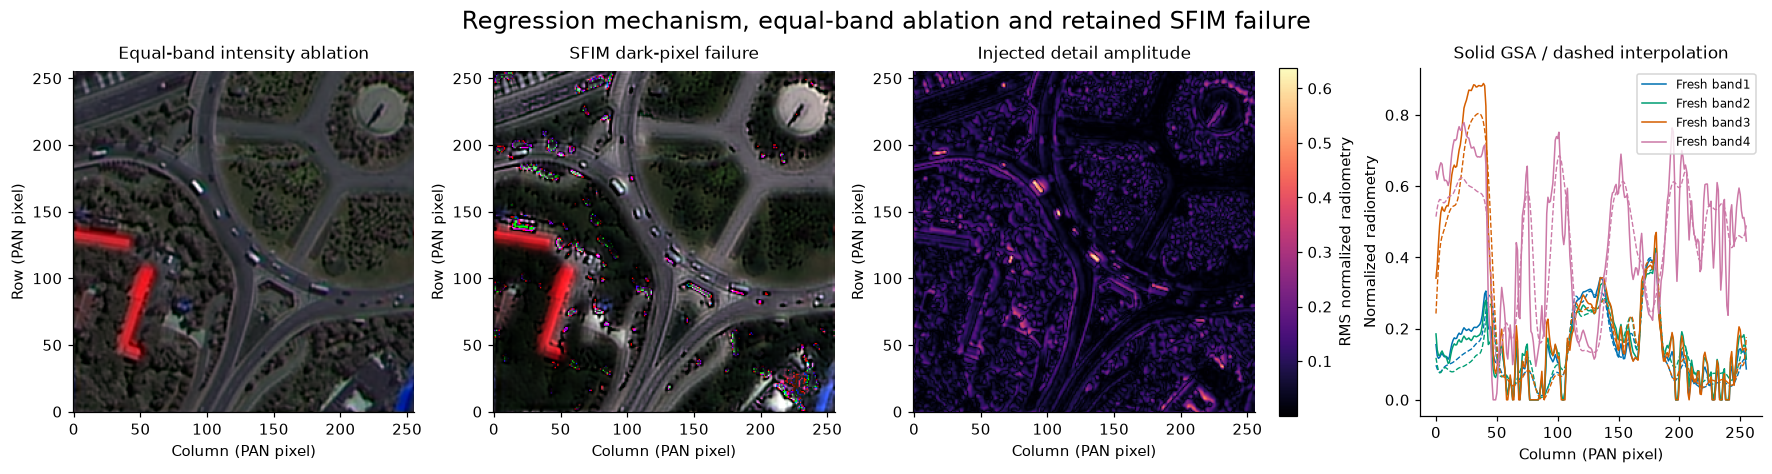

### 04 tradeoff

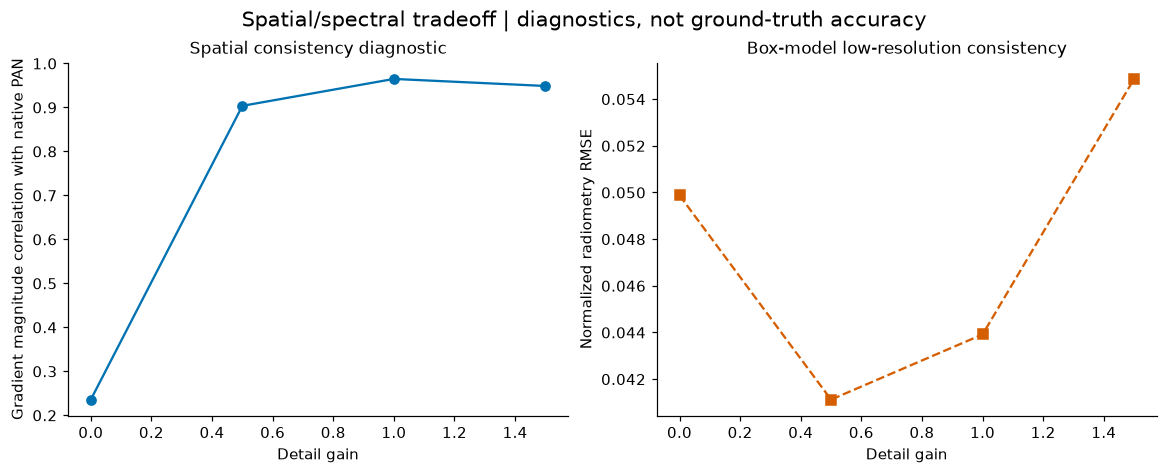

| experiment | NCC_vs_original | NRMSE_vs_original | gradient_correlation_PAN | box_model_MS_RMSE | clipped_fraction |
| --- | --- | --- | --- | --- | --- |
| detail gain=0 | 0.96513119 | 0.076943245 | 0.23578121 | 0.049877752 | 0.00090789795 |
| detail gain=0.5 | 0.99189898 | 0.037632642 | 0.90365756 | 0.041124213 | 0.017066956 |
| detail gain=1 | 1 | 0 | 0.96487095 | 0.043917812 | 0.053691864 |
| detail gain=1.5 | 0.99386856 | 0.034858342 | 0.94883151 | 0.054866912 | 0.087562561 |
| equal-band intensity | 0.95739375 | 0.085454152 | 0.99689476 | 0.082029392 | 0.009262085 |
| SFIM failure comparison | 0.95652153 | 0.087773132 | 0.66239503 | 0.055117606 | 0.050491333 |

Full active reconstruction plus experiments/figures: 1.400 s


In [2]:
figures,table,source_arrays=review(data,upstream)
for figure_name,figure in figures:
    display(Markdown('### '+figure_name.replace('_',' ')))
    display(figure)
    plt.close(figure)
keys=list(table[0])
lines=['| '+' | '.join(keys)+' |','| '+' | '.join(['---']*len(keys))+' |']
for row in table:
    lines.append('| '+' | '.join(str(row.get(k,'')) if not isinstance(row.get(k),float) else f'{row[k]:.8g}' for k in keys)+' |')
display(Markdown('\n'.join(lines)))
print(f'Full active reconstruction plus experiments/figures: {time.perf_counter()-started:.3f} s')
# Optional export path is private and supplied by the maintainer execution environment.
gallery=os.environ.get('IMAGING_PRIVATE_GALLERY')
if gallery:
    destination=Path(gallery)/ROOT.name;destination.mkdir(parents=True,exist_ok=True)
    for name,figure in figures:
        for ext in ['png','pdf','svg']:figure.savefig(destination/(name+'.'+ext),bbox_inches='tight')
    np.savez_compressed(destination/'figure_source_arrays.npz',**source_arrays)
    (destination/'experiment_metrics.json').write_text(json.dumps(table,indent=2,allow_nan=False))

## Evaluation and conclusion

The standalone Judge below evaluates the fresh file. Physical and mathematical validation are separate tests under `test/`. The spatial plates show what is actually constrained, while the ablations and residuals expose where method assumptions matter. Interpret the output as the declared regularized standard-method reconstruction of the supplied real observations; do not reinterpret it as independently measured truth.

In [3]:
import subprocess
result=subprocess.run([sys.executable,str(ROOT/'evaluation/judge.py'),'--prediction',str(ROOT/'output/reconstruction.npz'),'--report',str(ROOT/'output/judge_report.json')],capture_output=True,text=True)
print((ROOT/'output/judge_report.json').read_text())
assert result.returncode==0,result.stderr

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "reconstruction_ncc": 1.0,
    "reconstruction_nrmse": 0.0
  },
  "thresholds": {
    "reconstruction_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "reconstruction_nrmse": {
      "comparison": "<=",
      "boundary": 1e-06
    }
  },
  "errors": []
}

